In [ ]:
#code from any in class coding 08/28/24

In [5]:
#imports 
import pandas as pd
# import matplotlib.pyplot as plt
import matplotlib as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
import seaborn as sns

In [6]:
df = pd.read_csv("faults.csv")
print(df.head())

   X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  \
0         42         50     270900     270944           267           17   
1        645        651    2538079    2538108           108           10   
2        829        835    1553913    1553931            71            8   
3        853        860     369370     369415           176           13   
4       1289       1306     498078     498335          2409           60   

   Y_Perimeter  Sum_of_Luminosity  Minimum_of_Luminosity  \
0           44              24220                     76   
1           30              11397                     84   
2           19               7972                     99   
3           45              18996                     99   
4          260             246930                     37   

   Maximum_of_Luminosity  ...  Orientation_Index  Luminosity_Index  \
0                    108  ...             0.8182           -0.2913   
1                    123  ...             

                       X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  \
X_Minimum               1.000000   0.988314   0.041821   0.041807   
X_Maximum               0.988314   1.000000   0.052147   0.052135   
Y_Minimum               0.041821   0.052147   1.000000   1.000000   
Y_Maximum               0.041807   0.052135   1.000000   1.000000   
Pixels_Areas           -0.307322  -0.225399   0.017670   0.017840   
X_Perimeter            -0.258937  -0.186326   0.023843   0.024038   
Y_Perimeter            -0.118757  -0.090138   0.024150   0.024380   
Sum_of_Luminosity      -0.339045  -0.247052   0.007362   0.007499   
Minimum_of_Luminosity   0.237637   0.168649  -0.065703  -0.065733   
Maximum_of_Luminosity  -0.075554  -0.062392  -0.067785  -0.067776   
Length_of_Conveyer      0.316662   0.299390  -0.049211  -0.049219   
TypeOfSteel_A300        0.144319   0.112009   0.075164   0.075151   
TypeOfSteel_A400       -0.144319  -0.112009  -0.075164  -0.075151   
Steel_Plate_Thickness   0.136625  

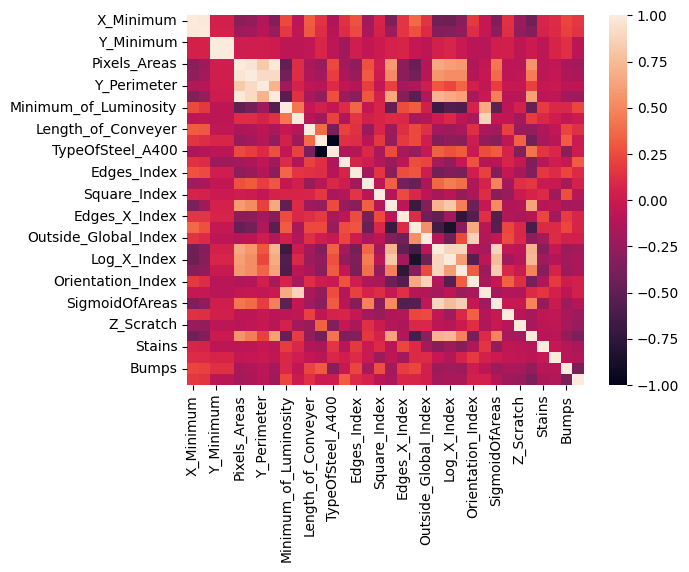

In [7]:
#visualize correlation
print(df.corr())
plot = sns.heatmap(df.corr())
#
#plt.show()
#plt.clf()

In [9]:
faults = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]

#create new column
df['fault'] = 0
print(df.columns)
print(df.head())

Index(['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas',
       'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity',
       'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer',
       'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness',
       'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index',
       'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas',
       'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index',
       'SigmoidOfAreas', 'Pastry', 'Z_Scratch', 'K_Scatch', 'Stains',
       'Dirtiness', 'Bumps', 'Other_Faults', 'fault'],
      dtype='object')
   X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  \
0         42         50     270900     270944           267           17   
1        645        651    2538079    2538108           108           10   
2        829        835    1553913    1553931            71            8   
3        853        860     369370  

In [12]:
#create new categorical var for each fault
# this will be int
for i in range(0, len(faults)):
    #idx list
    true_fault_indexes = df.loc[df[faults[i]] == 1].index.tolist()
    df.loc[true_fault_indexes, "fault"] = i + 1
    
print(df["fault"])

0       1
1       1
2       1
3       1
4       1
       ..
1936    7
1937    7
1938    7
1939    7
1940    7
Name: fault, Length: 1941, dtype: int64


In [14]:
# create our dataset -- train/test x and y, features and outcomes
drop_features = ["fault"] + faults
features = df.drop(drop_features, axis=1)
outcomes = df["fault"]

print(features.columns)
print(outcomes.head())

Index(['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas',
       'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity',
       'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer',
       'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness',
       'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index',
       'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas',
       'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index',
       'SigmoidOfAreas'],
      dtype='object')
0    1
1    1
2    1
3    1
4    1
Name: fault, dtype: int64


In [15]:
training_features, test_features, training_outcomes, test_outcomes = train_test_split(features, outcomes, test_size=0.1)
bayes_classifier = GaussianNB()
bayes_classifier.fit(training_features, training_outcomes)

#score it 
mean_accuracy = bayes_classifier.score(test_features, test_outcomes)
print(mean_accuracy)

0.5128205128205128
